In [ ]:
# Keep the existing torch/torchvision pair to preserve Colab CUDA compatibility.

%pip install -q "ultralytics==8.4.197" "scikit-learn>=1.4,<2" "pandas>=2,<3" "matplotlib>=3.8,<4" "pillow>=10" "requests>=2.31" "tqdm>=4.66"


In [ ]:
import os, sys, json, time, random, hashlib, re, math, shutil, zipfile, warnings
from pathlib import Path
from collections import defaultdict, Counter
from contextlib import nullcontext
import importlib.metadata as package_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import requests
from tqdm.auto import tqdm
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from ultralytics import YOLO
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
    average_precision_score, RocCurveDisplay, PrecisionRecallDisplay)
from IPython.display import display, Markdown

IN_COLAB = 'google.colab' in sys.modules
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0], '| Torch:', torch.__version__)
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU selected. For Colab, select a GPU runtime before full training.')
    torch.set_num_threads(min(8, os.cpu_count() or 1))
VERSIONS = {p: package_metadata.version(p) for p in
            ['torch','torchvision','ultralytics','numpy','pandas','scikit-learn','pillow']}


Python: 3.13.16 | Torch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [ ]:
USE_GOOGLE_DRIVE = True  # Colab only; local runs use BASE_DIR.
if IN_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/PPE_Classification')
else:
    BASE_DIR = Path.cwd() / 'ppe_classification_work'

DATA_DIR = (Path('/content/ppe_classification_data') if IN_COLAB
            else BASE_DIR / 'data')
RUN_MODE = 'full'                   # quick: smoke run; full: comparison budget.
EXPERIMENT_NAME = 'baseline_v1'
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 16 if DEVICE.type == 'cuda' else 8
NUM_WORKERS = 0                     # Avoid worker-spawn issues in notebook runtimes.
EPOCHS = 2 if RUN_MODE == 'quick' else 20
WARMUP_EPOCHS = 1 if RUN_MODE == 'quick' else 2
PATIENCE = 5
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 1e-4
TRAIN_CAP_PER_CLASS = 200 if RUN_MODE == 'quick' else None
CROP_PADDING = 0.20                 # Padding relative to each box dimension.
MIN_BOX_SIDE = 12                   # Reject regions below this pixel size.
TEMPORAL_BLOCK_SIZE = 100           # Group consecutive frame indices before splitting.
TEMPORAL_GUARD = 10                 # Drop frames near block boundaries.
MODEL_NAMES = ['resnet50', 'efficientnet_b0', 'yolov8n_cls']
TASK_CLASSES = {'mask': ['mask', 'no_mask'], 'shoes': ['shoes', 'no_shoes']}
assert RUN_MODE in {'quick','full'}

RUN_DIR = BASE_DIR / 'runs' / f'{EXPERIMENT_NAME}_{RUN_MODE}'
for p in [DATA_DIR, RUN_DIR]: p.mkdir(parents=True, exist_ok=True)
print('Results:', RUN_DIR)
print(f'{len(TASK_CLASSES)*len(MODEL_NAMES)} runs; up to {EPOCHS} epochs each.')

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
(RUN_DIR/'environment.json').write_text(json.dumps(VERSIONS, indent=2))


Mounted at /content/drive
Results: /content/drive/MyDrive/PPE_Classification/runs/baseline_v1_full
6 runs; up to 20 epochs each.


180

## Dataset and labels

Source: [PPEs v7, Personal Protective Equipment](https://universe.roboflow.com/personal-protective-equipment/ppes-kaxsi/dataset/7), distributed through the [keremberke mirror](https://huggingface.co/datasets/keremberke/protective-equipment-detection). Dataset card license: CC BY 4.0. Revision and archive checksums are pinned below.

| Original archive | mask | no_mask | shoes | no_shoes |
|---|---:|---:|---:|---:|
| train | 0 | 0 | 14 | 20 |
| valid | 253 | 640 | 639 | 525 |
| test | 16 | 21 | 102 | 61 |

The original training split has no mask examples. Pool the archives and rebuild grouped splits before training. Results use this revised protocol and are not comparable to the publisher's original split.

Negative samples require explicit `no_mask` or `no_shoes` labels. Missing annotations are not negative labels. COCO boxes are `[x, y, width, height]`; crops include relative context around each box.


In [ ]:
DATASET_REPO = 'keremberke/protective-equipment-detection'
DATASET_REVISION = '90d2c6da950a6168fcee20ec69e194a034f44eef'
ARCHIVES = {
    'train': {'bytes':903731317, 'sha256':'e5e3796e56892acf35631767af6138f622eafba875a53996e5618783c575cf39'},
    'valid': {'bytes':1125517514, 'sha256':'e86d9e44eb4d13ae81f7b93de75fb8955665f80136911d97262ea61ff3db694c'},
    'test': {'bytes':245068886, 'sha256':'16dfeef2e6e14bb188e40d0e856c12c48033e6a61b5b9230eaf53db97d3feb6e'},
}

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(4*1024*1024), b''): h.update(block)
    return h.hexdigest()

def download_archive(split):
    spec = ARCHIVES[split]
    path = DATA_DIR / 'archives' / f'{split}.zip'
    path.parent.mkdir(exist_ok=True)
    if path.exists() and path.stat().st_size == spec['bytes']:
        if sha256_file(path) == spec['sha256']:
            print('Verified cached', path.name); return path
    partial = path.with_suffix('.zip.part')
    url = f'https://huggingface.co/datasets/{DATASET_REPO}/resolve/{DATASET_REVISION}/data/{split}.zip'
    for attempt in range(3):
        try:
            # Restart partial archives; reuse only checksum-verified downloads.
            with requests.get(url, params={'download':'true','attempt':attempt},
                              stream=True, timeout=(30,120)) as r:
                r.raise_for_status()
                with open(partial, 'wb') as f, tqdm(total=spec['bytes'], unit='B',
                         unit_scale=True, desc=f'Download {split}') as bar:
                    for block in r.iter_content(1024*1024):
                        if block: f.write(block); bar.update(len(block))
            if partial.stat().st_size != spec['bytes'] or sha256_file(partial) != spec['sha256']:
                raise ValueError('Archive size/checksum mismatch. Retry the download cell.')
            os.replace(partial, path)
            return path
        except (requests.RequestException, ValueError) as exc:
            if attempt == 2: raise RuntimeError(f'Could not download {split}: {exc}') from exc
            print(f'Retrying {split}: {exc}')

archive_paths = {split: download_archive(split) for split in ARCHIVES}


Download train:   0%|          | 0.00/904M [00:00<?, ?B/s]

Download valid:   0%|          | 0.00/1.13G [00:00<?, ?B/s]

Download test:   0%|          | 0.00/245M [00:00<?, ?B/s]

## Crop preparation

Keep source IDs with every crop. Full-image pixel hashes and crop hashes support duplicate grouping; perceptual hashes are retained for inspection only. They do not establish session independence.

Invalid boxes and unreadable images are logged to `crop_issues.csv`. New evaluation data needs independently verified labels.


In [ ]:
def source_stem(filename):
    # Strip the Roboflow export suffix before source grouping.
    return Path(filename).name.split('.rf.')[0].lower()

def difference_hash(image):
    a = np.asarray(image.convert('L').resize((9,8), Image.Resampling.BILINEAR))
    bits = (a[:,1:] > a[:,:-1]).ravel()
    value = 0
    for bit in bits: value = (value << 1) | int(bit)
    return f'{value:016x}'

def read_coco_records(paths):
    records, counts = [], []
    wanted = {c for names in TASK_CLASSES.values() for c in names}
    for split, path in paths.items():
        with zipfile.ZipFile(path) as z:
            names = [n for n in z.namelist() if n.endswith('_annotations.coco.json')]
            if len(names) != 1: raise ValueError(f'Expected one COCO file in {path}')
            ann_file = names[0]; parent = str(Path(ann_file).parent)
            coco = json.loads(z.read(ann_file))
            categories = {c['id']:c['name'] for c in coco['categories']}
            images = {im['id']:im for im in coco['images']}
            count = Counter(categories[a['category_id']] for a in coco['annotations'])
            counts.append({'original_split':split, **{c:count[c] for c in sorted(wanted)}})
            members = set(z.namelist())
            for a in coco['annotations']:
                label = categories[a['category_id']]
                if label not in wanted or a.get('iscrowd',0): continue
                im = images[a['image_id']]
                member = im['file_name']
                if member not in members: member = (Path(parent)/member).as_posix()
                if member not in members: raise FileNotFoundError(im['file_name'])
                records.append({'archive':split, 'member':member,
                    'source_id':f"{split}:{im['id']}", 'filename':im['file_name'],
                    'annotation_id':str(a['id']), 'label':label, 'bbox':a['bbox']})
    return pd.DataFrame(records), pd.DataFrame(counts)

def prepare_crops(paths):
    crop_dir = DATA_DIR / f'crops_pad{CROP_PADDING}_min{MIN_BOX_SIDE}'
    manifest_path = crop_dir / 'manifest.csv'
    metadata_path = crop_dir / 'preparation.json'
    preparation = {'revision':DATASET_REVISION, 'padding':CROP_PADDING,
                   'min_box_side':MIN_BOX_SIDE, 'schema':1}
    if manifest_path.exists() and metadata_path.exists():
        if json.loads(metadata_path.read_text()) == preparation:
            cached = pd.read_csv(manifest_path, dtype={'dhash':str,'pixel_hash':str})
            if all(Path(p).exists() for p in cached.crop_path):
                _,original_counts = read_coco_records(paths)
                display(original_counts)
                original_counts.to_csv(RUN_DIR/'original_split_counts.csv',index=False)
                print('Using cached crops:',len(cached)); return cached
    crop_dir.mkdir(parents=True, exist_ok=True)
    records, original_counts = read_coco_records(paths)
    display(original_counts)
    original_counts.to_csv(RUN_DIR/'original_split_counts.csv', index=False)
    prepared, issues = [], []
    for split, path in paths.items():
        subset = records[records.archive == split]
        with zipfile.ZipFile(path) as z:
            for source_id, annotations in tqdm(subset.groupby('source_id'), desc=f'Crop {split}'):
                try:
                    image = Image.open(z.open(annotations.iloc[0].member)).convert('RGB')
                    image.load()
                except Exception as exc:
                    issues.append({'source_id':source_id,'reason':str(exc)}); continue
                pix_hash = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
                dhash = difference_hash(image)
                for _, row in annotations.iterrows():
                    x,y,w,h = map(float,row.bbox)
                    if not np.isfinite([x,y,w,h]).all() or min(w,h) < MIN_BOX_SIDE:
                        issues.append({'source_id':source_id,'reason':'small/invalid box'}); continue
                    left,top = max(0,math.floor(x-w*CROP_PADDING)), max(0,math.floor(y-h*CROP_PADDING))
                    right,bottom = min(image.width,math.ceil(x+w*(1+CROP_PADDING))), min(image.height,math.ceil(y+h*(1+CROP_PADDING)))
                    if right <= left or bottom <= top:
                        issues.append({'source_id':source_id,'reason':'box outside image'}); continue
                    crop_path = crop_dir / f"{split}_{row.annotation_id}_{row.label}.png"
                    image.crop((left,top,right,bottom)).save(crop_path)
                    prepared.append({'source_id':source_id,'archive':split,
                        'filename':row.filename, 'source_stem':source_stem(row.filename),
                        'annotation_id':row.annotation_id, 'label':row.label,
                        'crop_path':str(crop_path.resolve()), 'pixel_hash':pix_hash,
                        'dhash':dhash, 'crop_width':right-left,'crop_height':bottom-top})
    frame = pd.DataFrame(prepared)
    if frame.empty: raise ValueError('No usable crops. Inspect the source annotations.')
    frame.to_csv(manifest_path,index=False)
    pd.DataFrame(issues, columns=['source_id','reason']).to_csv(RUN_DIR/'crop_issues.csv',index=False)
    metadata_path.write_text(json.dumps(preparation,indent=2))
    print('Crops:',len(frame),'| skipped boxes/images:',len(issues))
    return frame

all_crops = prepare_crops(archive_paths)
display(all_crops.groupby('label').agg(crops=('label','size'), source_images=('source_id','nunique')))


,original_split,mask,no_mask,no_shoes,shoes
0,train,0,0,20,14
1,valid,253,640,525,639
2,test,16,21,61,102


Crop train:   0%|          | 0/12 [00:00<?, ?it/s]

Crop valid:   0%|          | 0/1226 [00:00<?, ?it/s]

Crop test:   0%|          | 0/91 [00:00<?, ?it/s]

Crops: 2291 | skipped boxes/images: 0


,crops,source_images
label,,
mask,269,269
no_mask,661,661
no_shoes,606,345
shoes,755,406


## Label review

Inspect the sampled regions before training. Some `shoes` annotations depict detached shoes; the label does not establish that a person is wearing protective footwear. `no_mask` is a region label, not a task-specific compliance decision.

Workshop use still requires person-to-PPE association, approved task rules, representative data, and an unassessable-view state.


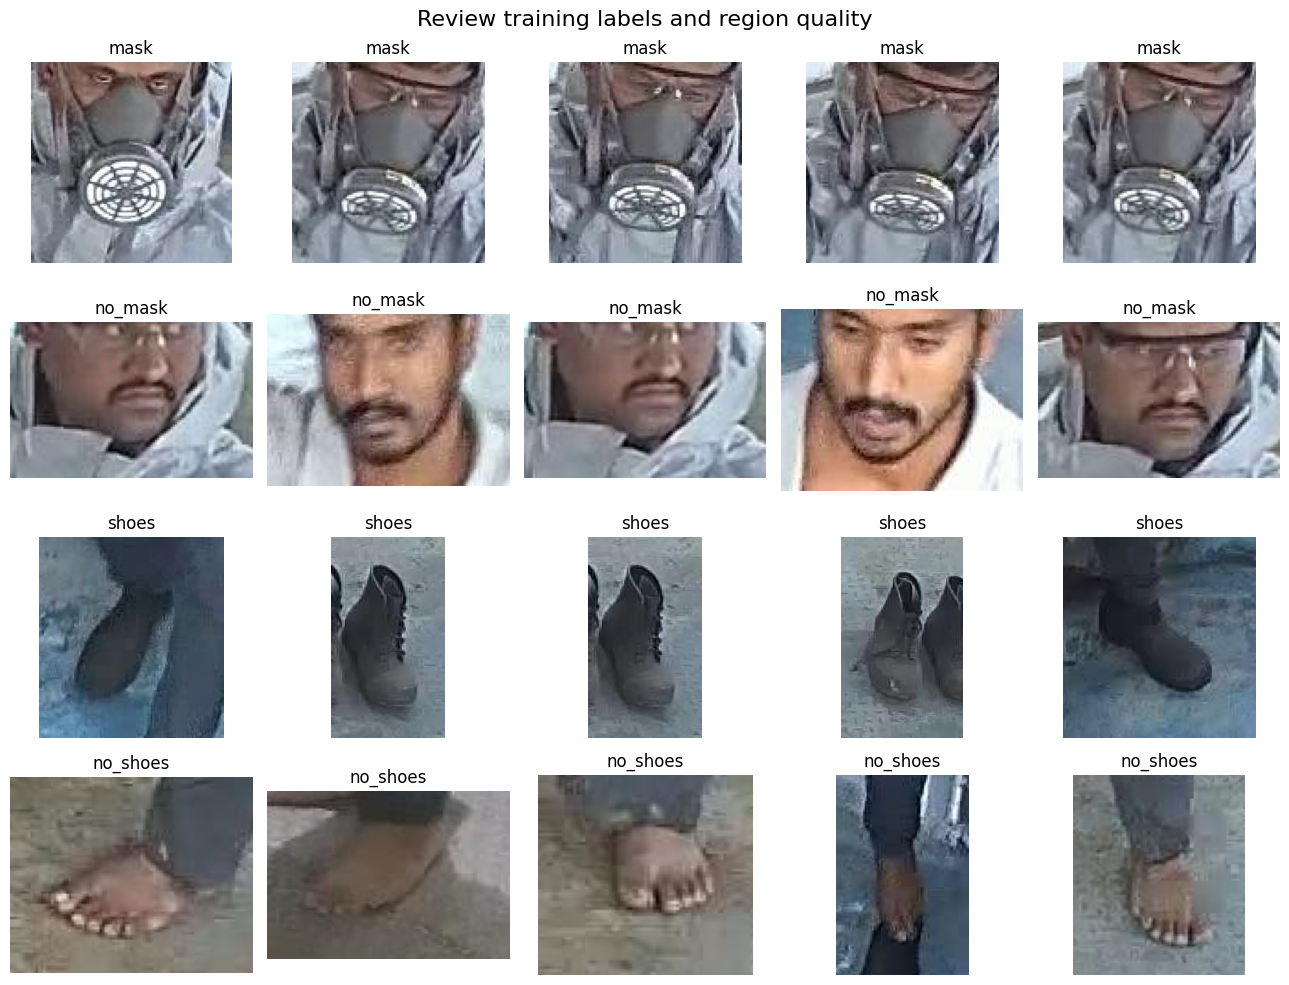

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(13,10))
for row, label in enumerate(['mask','no_mask','shoes','no_shoes']):
    examples = all_crops[all_crops.label == label].sample(
        n=min(5, (all_crops.label == label).sum()), random_state=SEED)
    for ax in axes[row]: ax.axis('off')
    for ax, (_, item) in zip(axes[row], examples.iterrows()):
        ax.imshow(Image.open(item.crop_path)); ax.set_title(label)
plt.suptitle('Review training labels and region quality',fontsize=16)
plt.tight_layout(); plt.savefig(RUN_DIR/'label_examples.png',dpi=150); plt.show()


## Temporal grouping

Protocol: within-recording temporal-block baseline. Keep numbered frames in 100-frame blocks and drop 10 frame numbers on either side of each boundary. Retained blocks have gaps of at least 20 frame numbers; these are filename indices, not timestamps.

Merge crops sharing a source image, pre-export filename, decoded full-image pixels, temporal block, or identical crop pixels. A recording can still span multiple splits. Worker and session independence are not established by filenames or perceptual hashes.

Optional `BASE_DIR/source_groups.csv` uses `filename,source_group` to merge known recordings or sessions. It cannot split automatic groups. If this leaves insufficient groups, collect more independent data. For workshop evaluation, split by worker/session before cropping.


In [ ]:
class UnionFind:
    def __init__(self, items): self.parent = {x:x for x in items}
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b): self.parent[self.find(b)] = self.find(a)

def temporal_block(stem):
    match = re.match(r'^frame(\d+)',stem)
    if match: family,number = 'frame_family',int(match.group(1))
    else:
        match = re.match(r'^ppe_data_(\d+)',stem)
        if match: family,number = 'ppe_data',int(match.group(1))
        else:
            match = re.match(r'^(nvr.*?)[-_](\d+)(?:_jpg|_png|_jpeg)?$',stem)
            if not match: return None,False
            family,number = match.group(1),int(match.group(2))
    position = number % TEMPORAL_BLOCK_SIZE
    discard = position < TEMPORAL_GUARD or position >= TEMPORAL_BLOCK_SIZE-TEMPORAL_GUARD
    return f'{family}:block{number//TEMPORAL_BLOCK_SIZE}',discard

def group_sources(frame):
    boundary_sources = {r.source_id for r in frame.drop_duplicates('source_id').itertuples()
                        if temporal_block(r.source_stem)[1]}
    frame[frame.source_id.isin(boundary_sources)].to_csv(RUN_DIR/'temporal_guard_exclusions.csv',index=False)
    frame = frame[~frame.source_id.isin(boundary_sources)].copy()
    sources = frame.drop_duplicates('source_id').copy().reset_index(drop=True)
    uf = UnionFind(sources.source_id)
    seen = {}
    override_path = BASE_DIR/'source_groups.csv'
    overrides = {}
    if override_path.exists():
        custom = pd.read_csv(override_path).dropna(subset=['filename','source_group'])
        overrides = dict(zip(custom.filename.astype(str),custom.source_group.astype(str)))
    for row in sources.itertuples():
        keys = [('name',row.source_stem), ('pixels',row.pixel_hash)]
        block,_ = temporal_block(row.source_stem)
        if block: keys.append(('temporal_block',block))
        if row.filename in overrides: keys.append(('manual',overrides[row.filename]))
        for key in keys:
            if key in seen: uf.union(row.source_id,seen[key])
            else: seen[key] = row.source_id
    ids = sources.source_id.tolist()
    mapping = {sid:uf.find(sid) for sid in ids}
    result = frame.copy(); result['group'] = result.source_id.map(mapping)
    # Deduplicate same-label crop pixels.
    crop_hashes = {}
    for path in tqdm(result.crop_path.unique(),desc='Hash crop pixels'):
        with Image.open(path) as im:
            crop_hashes[path] = hashlib.sha256(str(im.size).encode()+im.tobytes()).hexdigest()
    result['crop_hash'] = result.crop_path.map(crop_hashes)
    # Merge source groups connected by identical crops.
    crop_seen = {}
    for row in result.itertuples():
        if row.crop_hash in crop_seen: uf.union(row.source_id,crop_seen[row.crop_hash])
        else: crop_seen[row.crop_hash] = row.source_id
    result['group'] = result.source_id.map(lambda sid:uf.find(sid))
    conflicting = result.groupby('crop_hash').label.nunique()
    bad = set(conflicting[conflicting > 1].index)
    conflicts = result[result.crop_hash.isin(bad)]
    conflicts.to_csv(RUN_DIR/'conflicting_crop_labels.csv',index=False)
    result = result[~result.crop_hash.isin(bad)].drop_duplicates(['crop_hash','label']).copy()
    print('Excluded boundary source images:',len(boundary_sources))
    print('Excluded conflicting crops:',len(conflicts))
    return result

grouped_crops = group_sources(all_crops)
display(grouped_crops.groupby('label').agg(crops=('label','size'),groups=('group','nunique')))


Hash crop pixels:   0%|          | 0/1846 [00:00<?, ?it/s]

Excluded boundary source images: 262
Excluded conflicting crops: 0


,crops,groups
label,,
mask,221,11
no_mask,518,23
no_shoes,465,15
shoes,589,16


## Shared train / validation / test split

Target proportions: 70 / 15 / 15, with both classes present for each task. Group sizes can prevent exact proportions. The split search uses labels and group sizes only; all six runs share the assignment.

Training data supplies class weights. Validation macro F1 selects checkpoints and models. Test predictions do not control early stopping, thresholds, or hyperparameters. Reserve independent workshop sessions for a final deployment evaluation.


split,train,val,test
label,,,
mask,156,43,22
no_mask,317,136,65
no_shoes,350,82,33
shoes,403,99,87


Source groups per split: {'test': 6, 'train': 28, 'val': 6}
Rows per split: {'train': 0.684, 'val': 0.201, 'test': 0.115}


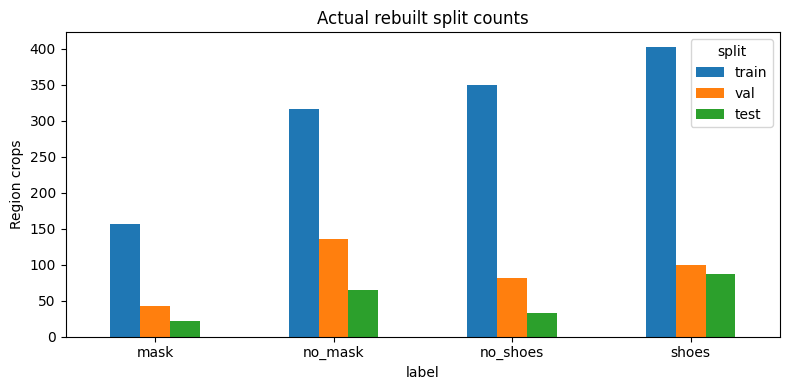

In [ ]:
def grouped_three_way_split(frame, attempts=1000):
    labels = sorted(frame.label.unique())
    if len(labels) != 4: raise ValueError('All four target labels are required.')
    if frame.group.nunique() < 3: raise ValueError('Need at least three source blocks/groups.')
    for label in labels:
        if frame[frame.label == label].group.nunique() < 3:
            raise ValueError(f'{label}: fewer than 3 source blocks/groups. Add labelled sources; do not split individual crops randomly.')
    target = np.array([0.70,0.15,0.15])
    totals = frame.label.value_counts().reindex(labels).to_numpy()
    best = None
    for attempt in range(attempts):
        first = GroupShuffleSplit(n_splits=1,test_size=0.30,random_state=SEED+attempt)
        train_idx, hold_idx = next(first.split(frame,groups=frame.group))
        hold = frame.iloc[hold_idx]
        if hold.group.nunique() < 2: continue
        second = GroupShuffleSplit(n_splits=1,test_size=0.5,random_state=SEED+attempt+10000)
        val_rel, test_rel = next(second.split(hold,groups=hold.group))
        indices = [train_idx,hold_idx[val_rel],hold_idx[test_rel]]
        counts = np.array([frame.iloc[idx].label.value_counts().reindex(labels,fill_value=0).to_numpy() for idx in indices])
        if (counts < 5).any(): continue
        score = np.abs(counts/totals[None,:]-target[:,None]).mean()
        if best is None or score < best[0]: best = (score,indices)
    if best is None:
        raise ValueError('No usable grouped split. Inspect group counts and obtain more independent sources rather than weakening the split.')
    result = frame.copy(); result['split'] = ''
    for name,idx in zip(['train','val','test'],best[1]):
        result.loc[result.index[idx],'split'] = name
    assert result.groupby('group').split.nunique().max() == 1
    assert result.groupby('source_id').split.nunique().max() == 1
    assert result.groupby('pixel_hash').split.nunique().max() == 1
    assert result.groupby('crop_hash').split.nunique().max() == 1
    return result

manifest = grouped_three_way_split(grouped_crops)
if TRAIN_CAP_PER_CLASS is not None:
    train_small = pd.concat([part.sample(min(len(part),TRAIN_CAP_PER_CLASS),random_state=SEED)
        for _,part in manifest[manifest.split == 'train'].groupby('label')])
    manifest = pd.concat([train_small,manifest[manifest.split != 'train']]).sort_index()
manifest = manifest.reset_index(drop=True)
display(pd.crosstab(manifest.label,manifest.split)[['train','val','test']])
print('Source groups per split:',manifest.groupby('split').group.nunique().to_dict())
print('Rows per split:',manifest.split.value_counts(normalize=True).round(3).to_dict())

# Reject resume if the experiment signature has changed.
fingerprint_columns = ['source_id','annotation_id','label','crop_hash','group','split']
DATA_FINGERPRINT = hashlib.sha256(manifest[fingerprint_columns].to_csv(index=False).encode()).hexdigest()
RUN_CONFIG = dict(mode=RUN_MODE,seed=SEED,image_size=IMAGE_SIZE,batch_size=BATCH_SIZE,
    epochs=EPOCHS,warmup_epochs=WARMUP_EPOCHS,patience=PATIENCE,head_lr=HEAD_LR,
    backbone_lr=BACKBONE_LR,weight_decay=WEIGHT_DECAY,dataset_revision=DATASET_REVISION,
    data_fingerprint=DATA_FINGERPRINT,model_names=MODEL_NAMES,classes=TASK_CLASSES,
    crop_padding=CROP_PADDING,min_box_side=MIN_BOX_SIDE,temporal_block_size=TEMPORAL_BLOCK_SIZE,
    temporal_guard=TEMPORAL_GUARD,split_policy='within_recording_temporal_blocks',
    versions=VERSIONS)
config_path = RUN_DIR/'run_config.json'
if config_path.exists() and json.loads(config_path.read_text()) != RUN_CONFIG:
    raise ValueError('This run folder has different settings/data/library versions. Change EXPERIMENT_NAME to keep experiments separate.')
config_path.write_text(json.dumps(RUN_CONFIG,indent=2))
manifest.to_csv(RUN_DIR/'split_manifest.csv',index=False)
fig,ax = plt.subplots(figsize=(8,4))
pd.crosstab(manifest.label,manifest.split)[['train','val','test']].plot.bar(ax=ax)
ax.set_ylabel('Region crops'); ax.set_title('Actual rebuilt split counts'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(RUN_DIR/'split_counts.png',dpi=150); plt.show()


## Preprocessing

Preserve crop aspect ratio and pad to 224 × 224. Training adds horizontal flips and small brightness/contrast changes; validation and test transforms are deterministic.

ResNet and EfficientNet use ImageNet normalization. YOLOv8-cls uses inputs in `[0, 1]`. Crop geometry, augmentation policy, optimizer, epoch budget, and split are otherwise shared. Loss weights come from training counts only.


In [ ]:
class SquarePadResize:
    def __init__(self,size): self.size = size
    def __call__(self,image):
        return ImageOps.pad(image,(self.size,self.size),method=Image.Resampling.BILINEAR,
                            color=(114,114,114),centering=(0.5,0.5))

def make_transform(model_name,training=False):
    steps = [SquarePadResize(IMAGE_SIZE)]
    if training:
        steps += [transforms.RandomHorizontalFlip(0.5),
                  transforms.ColorJitter(brightness=0.15,contrast=0.15,saturation=0.10)]
    steps += [transforms.ToTensor()]
    if model_name != 'yolov8n_cls':
        steps += [transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]
    return transforms.Compose(steps)

class CropDataset(Dataset):
    def __init__(self,rows,classes,transform):
        self.rows = rows.reset_index(drop=True); self.classes = classes
        self.to_id = {c:i for i,c in enumerate(classes)}; self.transform = transform
    def __len__(self): return len(self.rows)
    def __getitem__(self,index):
        row = self.rows.iloc[index]
        with Image.open(row.crop_path) as image:
            tensor = self.transform(image.convert('RGB'))
        return tensor,self.to_id[row.label]

def make_loader(rows,task,model_name,training=False,epoch=0):
    dataset = CropDataset(rows,TASK_CLASSES[task],make_transform(model_name,training))
    generator = torch.Generator().manual_seed(SEED+epoch)
    return DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=training,
        num_workers=NUM_WORKERS,pin_memory=DEVICE.type=='cuda',generator=generator)

def build_model(name,pretrained=True):
    if name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features,2)
    elif name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features,2)
    elif name == 'yolov8n_cls':
        # Use pretrained YOLO weights with the shared PyTorch training loop.
        
        model = YOLO('yolov8n-cls.pt' if pretrained else 'yolov8n-cls.yaml').model
        head = model.model[-1]
        head.linear = nn.Linear(head.linear.in_features,2)
        model.names = {0:'present',1:'missing'}
        model.nc = 2
    else: raise ValueError(name)
    return model.to(DEVICE)

def classification_head(model,name):
    if name == 'resnet50': return model.fc
    if name == 'efficientnet_b0': return model.classifier
    return model.model[-1].linear

def get_logits(model,images):
    output = model(images)
    # Eval output includes probabilities and logits.
    # Cross-entropy expects logits.
    return output[1] if isinstance(output,tuple) else output

print('Data loaders and model factories are ready. No training has started yet.')


Data loaders and model factories are ready. No training has started yet.


## Training and checkpoints

AdamW with a frozen-backbone warmup, followed by fine-tuning at a lower backbone learning rate. Reduce learning rate on stalled validation loss. Save the checkpoint with best validation macro F1 and stop after the configured patience.

`last.pt` stores epoch-level resume state, optimizer, scheduler, and history. `best.pt` stores validation-selected weights. All three architectures use this notebook's PyTorch checkpoint format, including YOLO; reload with `restore_model()`, not `YOLO('best.pt')`.

Equal epoch budgets do not imply equal compute or exhaustive architecture tuning.


In [ ]:
def atomic_torch_save(payload,path):
    temporary = path.with_suffix('.tmp')
    torch.save(payload,temporary); os.replace(temporary,path)

def load_checkpoint(path):
    # Checkpoint loading uses pickle; load trusted files only.
    return torch.load(path,map_location='cpu',weights_only=True)

def evaluate_loader(model,loader,criterion=None):
    model.eval(); all_y,all_prob = [],[]; loss_sum = 0.0
    with torch.inference_mode():
        for images,labels in loader:
            images,labels = images.to(DEVICE),labels.to(DEVICE)
            logits = get_logits(model,images)
            if criterion is not None: loss_sum += criterion(logits,labels).item()*len(labels)
            all_y.extend(labels.cpu().tolist())
            all_prob.extend(torch.softmax(logits,dim=1).cpu().numpy().tolist())
    y = np.asarray(all_y); probabilities = np.asarray(all_prob)
    pred = probabilities.argmax(1)
    # Accumulate loss by sample count.
    return {'loss':loss_sum/max(1,len(y)), 'accuracy':accuracy_score(y,pred),
            'macro_f1':f1_score(y,pred,average='macro',zero_division=0),
            'y':y,'probabilities':probabilities,'pred':pred}

def train_one(task,name):
    seed_everything(SEED)
    folder = RUN_DIR/task/name; folder.mkdir(parents=True,exist_ok=True)
    last_path,best_path = folder/'last.pt',folder/'best.pt'
    metadata_path = folder/'training_summary.json'
    if metadata_path.exists() and best_path.exists():
        metadata = json.loads(metadata_path.read_text())
        print(f'{task}/{name}: already finished ({metadata["completed_epochs"]} epochs).')
        return metadata
    train_rows = manifest[(manifest.label.isin(TASK_CLASSES[task])) & (manifest.split=='train')]
    val_rows = manifest[(manifest.label.isin(TASK_CLASSES[task])) & (manifest.split=='val')]
    counts = train_rows.label.value_counts().reindex(TASK_CLASSES[task]).to_numpy()
    if (counts <= 0).any(): raise ValueError('Both training classes must be present.')
    weights = torch.tensor(counts.sum()/(2*counts),dtype=torch.float32,device=DEVICE)
    # Apply class weights per example before averaging.
    weighted_loss = nn.CrossEntropyLoss(weight=weights,reduction='none')
    train_criterion = lambda logits,y: weighted_loss(logits,y).mean()
    val_criterion = nn.CrossEntropyLoss()  # Keep validation loss unweighted.
    previous = load_checkpoint(last_path) if last_path.exists() else None
    model = build_model(name,pretrained=previous is None)
    head = classification_head(model,name)
    head_ids = {id(p) for p in head.parameters()}
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    optimizer = torch.optim.AdamW([
        {'params':backbone_params,'lr':BACKBONE_LR},
        {'params':list(head.parameters()),'lr':HEAD_LR}],weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.5,patience=2)
    scaler = torch.amp.GradScaler('cuda',enabled=DEVICE.type=='cuda')
    history, best_score, bad_epochs, start_epoch, elapsed_before = [],-1.0,0,0,0.0
    if previous is not None:
        if previous['run_config'] != RUN_CONFIG: raise ValueError('Checkpoint configuration does not match.')
        model.load_state_dict(previous['model_state'])
        optimizer.load_state_dict(previous['optimizer_state'])
        # Move restored optimizer state to the active device.
        for state in optimizer.state.values():
            for key,value in state.items():
                if torch.is_tensor(value): state[key] = value.to(DEVICE)
        scheduler.load_state_dict(previous['scheduler_state'])
        scaler.load_state_dict(previous['scaler_state'])
        history = previous['history']; best_score = previous['best_score']
        bad_epochs = previous['bad_epochs']; start_epoch = previous['epoch']+1
        elapsed_before = previous['training_seconds']
        print(f'Resuming {task}/{name} at epoch {start_epoch+1}')
    val_loader = make_loader(val_rows,task,name)
    start = time.perf_counter()
    for epoch in range(start_epoch,EPOCHS):
        if bad_epochs >= PATIENCE: break
        seed_everything(SEED+epoch)
        warmup = epoch < WARMUP_EPOCHS
        for p in model.parameters(): p.requires_grad_(not warmup)
        for p in head.parameters(): p.requires_grad_(True)
        model.train()
        if warmup:
            model.eval()  # Freeze backbone batch-normalization statistics during warmup.
            head.train()
        train_loader = make_loader(train_rows,task,name,training=True,epoch=epoch)
        loss_total, correct, total = 0.0,0,0
        progress = tqdm(train_loader,desc=f'{task}/{name} epoch {epoch+1}/{EPOCHS}',leave=False)
        for images,labels in progress:
            images,labels = images.to(DEVICE),labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type,enabled=DEVICE.type=='cuda'):
                logits = get_logits(model,images); loss = train_criterion(logits,labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(),5.0)
            scaler.step(optimizer); scaler.update()
            loss_total += loss.item()*len(labels)
            correct += (logits.argmax(1)==labels).sum().item(); total += len(labels)
            progress.set_postfix(loss=f'{loss.item():.3f}')
        validation = evaluate_loader(model,val_loader,val_criterion)
        scheduler.step(validation['loss'])
        row = {'epoch':epoch+1,'train_loss':loss_total/total,'train_accuracy':correct/total,
               'val_loss':validation['loss'],'val_accuracy':validation['accuracy'],
               'val_macro_f1':validation['macro_f1'],'backbone_lr':optimizer.param_groups[0]['lr']}
        history.append(row)
        improved = validation['macro_f1'] > best_score+1e-6
        if improved: best_score = validation['macro_f1']; bad_epochs = 0
        else: bad_epochs += 1
        payload = {'architecture':name,'task':task,'classes':TASK_CLASSES[task],
            'image_size':IMAGE_SIZE,'run_config':RUN_CONFIG,'epoch':epoch,
            'model_state':model.state_dict(),'optimizer_state':optimizer.state_dict(),
            'scheduler_state':scheduler.state_dict(),'scaler_state':scaler.state_dict(),
            'history':history,'best_score':float(best_score),'bad_epochs':bad_epochs,
            'training_seconds':elapsed_before+time.perf_counter()-start}
        if improved:
            best_payload = {k:v for k,v in payload.items() if k not in
                            ['optimizer_state','scheduler_state','scaler_state']}
            atomic_torch_save(best_payload,best_path)
        atomic_torch_save(payload,last_path)
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        print(f"{task}/{name}: epoch {epoch+1}, val F1={row['val_macro_f1']:.3f}, val accuracy={row['val_accuracy']:.3f}" + (' [best]' if improved else ''))
    summary = {'task':task,'model':name,'best_val_macro_f1':float(best_score),
        'completed_epochs':len(history),'training_seconds':elapsed_before+time.perf_counter()-start,
        'parameters':sum(p.numel() for p in model.parameters()),
        'best_checkpoint':str(best_path)}
    metadata_path.write_text(json.dumps(summary,indent=2))
    del model,optimizer,scaler,previous
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
    return summary


## Mask training

Three independent ImageNet-initialized runs. Resume starts after the last completed epoch. Changing batch size or other saved settings requires a new experiment name.


In [ ]:
mask_training = [train_one('mask',name) for name in MODEL_NAMES]
display(pd.DataFrame(mask_training))


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 208MB/s]


mask/resnet50 epoch 1/20:   0%|          | 0/30 [00:00<?, ?it/s]

mask/resnet50: epoch 1, val F1=0.992, val accuracy=0.994 [best]


mask/resnet50 epoch 2/20:   0%|          | 0/30 [00:00<?, ?it/s]

mask/resnet50: epoch 2, val F1=0.992, val accuracy=0.994


... (38 outputs left out)

mask/yolov8n_cls: epoch 6, val F1=1.000, val accuracy=1.000


mask/yolov8n_cls epoch 7/20:   0%|          | 0/30 [00:00<?, ?it/s]

mask/yolov8n_cls: epoch 7, val F1=1.000, val accuracy=1.000


,task,model,best_val_macro_f1,completed_epochs,training_seconds,parameters,best_checkpoint
0,mask,resnet50,1.0,9,79.737932,23512130,/content/drive/MyDrive/PPE_Classification/runs...
1,mask,efficientnet_b0,1.0,6,48.983568,4010110,/content/drive/MyDrive/PPE_Classification/runs...
2,mask,yolov8n_cls,1.0,7,28.344168,1440850,/content/drive/MyDrive/PPE_Classification/runs...


## Footwear training

Train separate models from the original pretrained weights. Mask checkpoints are not reused.


In [ ]:
shoe_training = [train_one('shoes',name) for name in MODEL_NAMES]
display(pd.DataFrame(shoe_training))


shoes/resnet50 epoch 1/20:   0%|          | 0/48 [00:00<?, ?it/s]

shoes/resnet50: epoch 1, val F1=0.932, val accuracy=0.934 [best]


shoes/resnet50 epoch 2/20:   0%|          | 0/48 [00:00<?, ?it/s]

shoes/resnet50: epoch 2, val F1=0.949, val accuracy=0.950 [best]


shoes/resnet50 epoch 3/20:   0%|          | 0/48 [00:00<?, ?it/s]

shoes/resnet50: epoch 3, val F1=0.961, val accuracy=0.961 [best]


... (71 outputs left out)

shoes/yolov8n_cls: epoch 16, val F1=0.972, val accuracy=0.972


shoes/yolov8n_cls epoch 17/20:   0%|          | 0/48 [00:00<?, ?it/s]

shoes/yolov8n_cls: epoch 17, val F1=0.961, val accuracy=0.961


,task,model,best_val_macro_f1,completed_epochs,training_seconds,parameters,best_checkpoint
0,shoes,resnet50,0.988827,9,105.246278,23512130,/content/drive/MyDrive/PPE_Classification/runs...
1,shoes,efficientnet_b0,1.000000,14,127.559345,4010110,/content/drive/MyDrive/PPE_Classification/runs...
2,shoes,yolov8n_cls,0.971961,17,95.379824,1440850,/content/drive/MyDrive/PPE_Classification/runs...


## Learning curves

Training metrics use augmented crops; validation metrics use deterministic held-out crops. Training loss is class-weighted, while validation loss is unweighted. The dashed line marks the saved validation-F1 checkpoint.


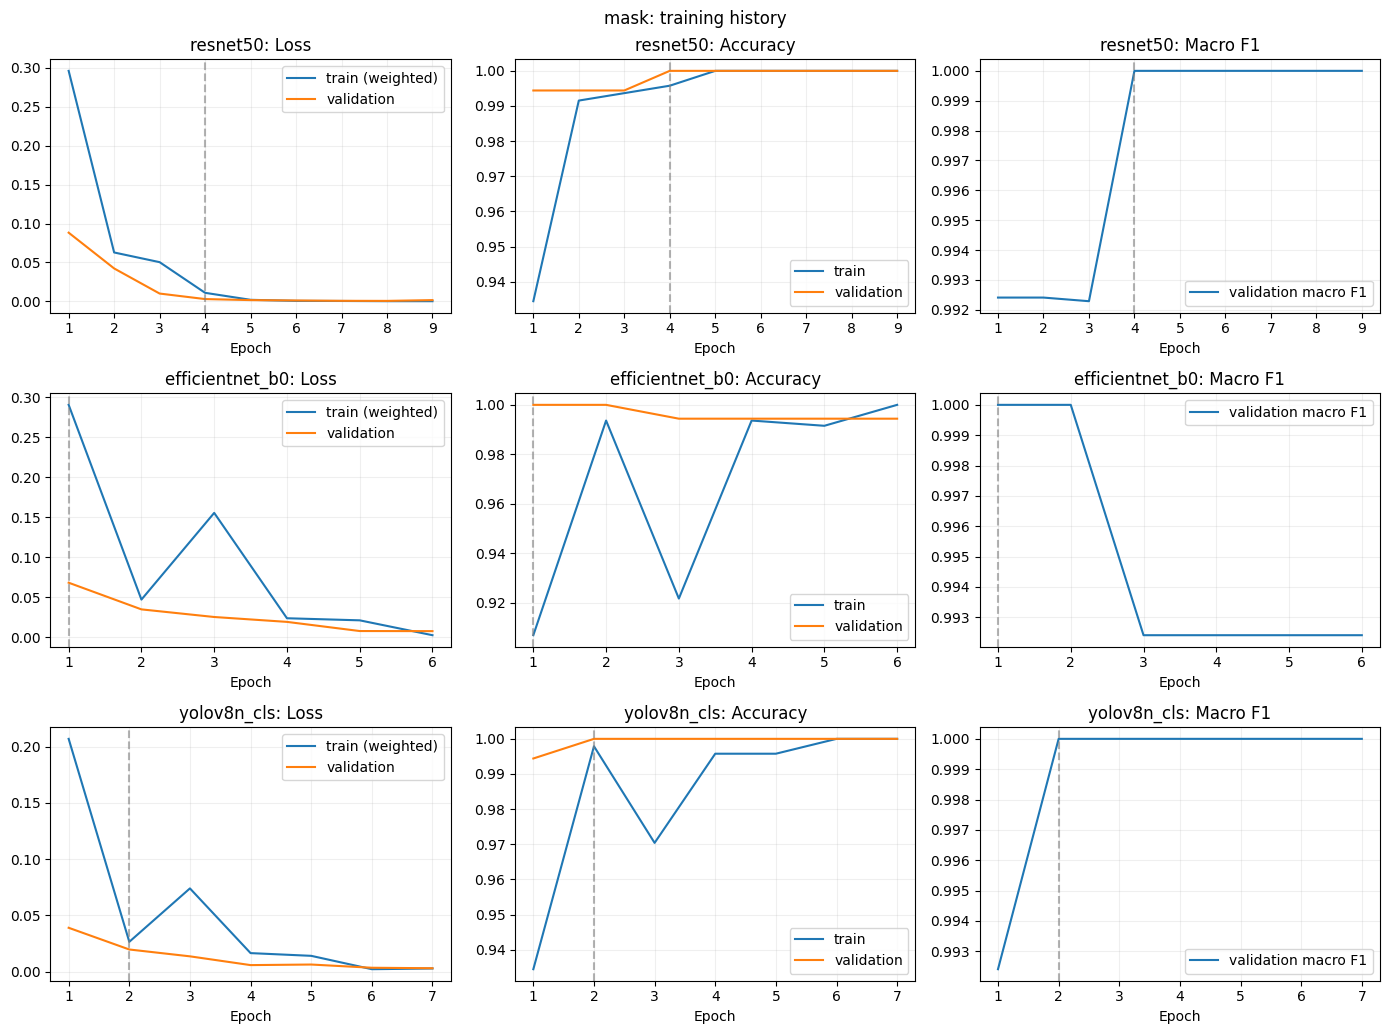

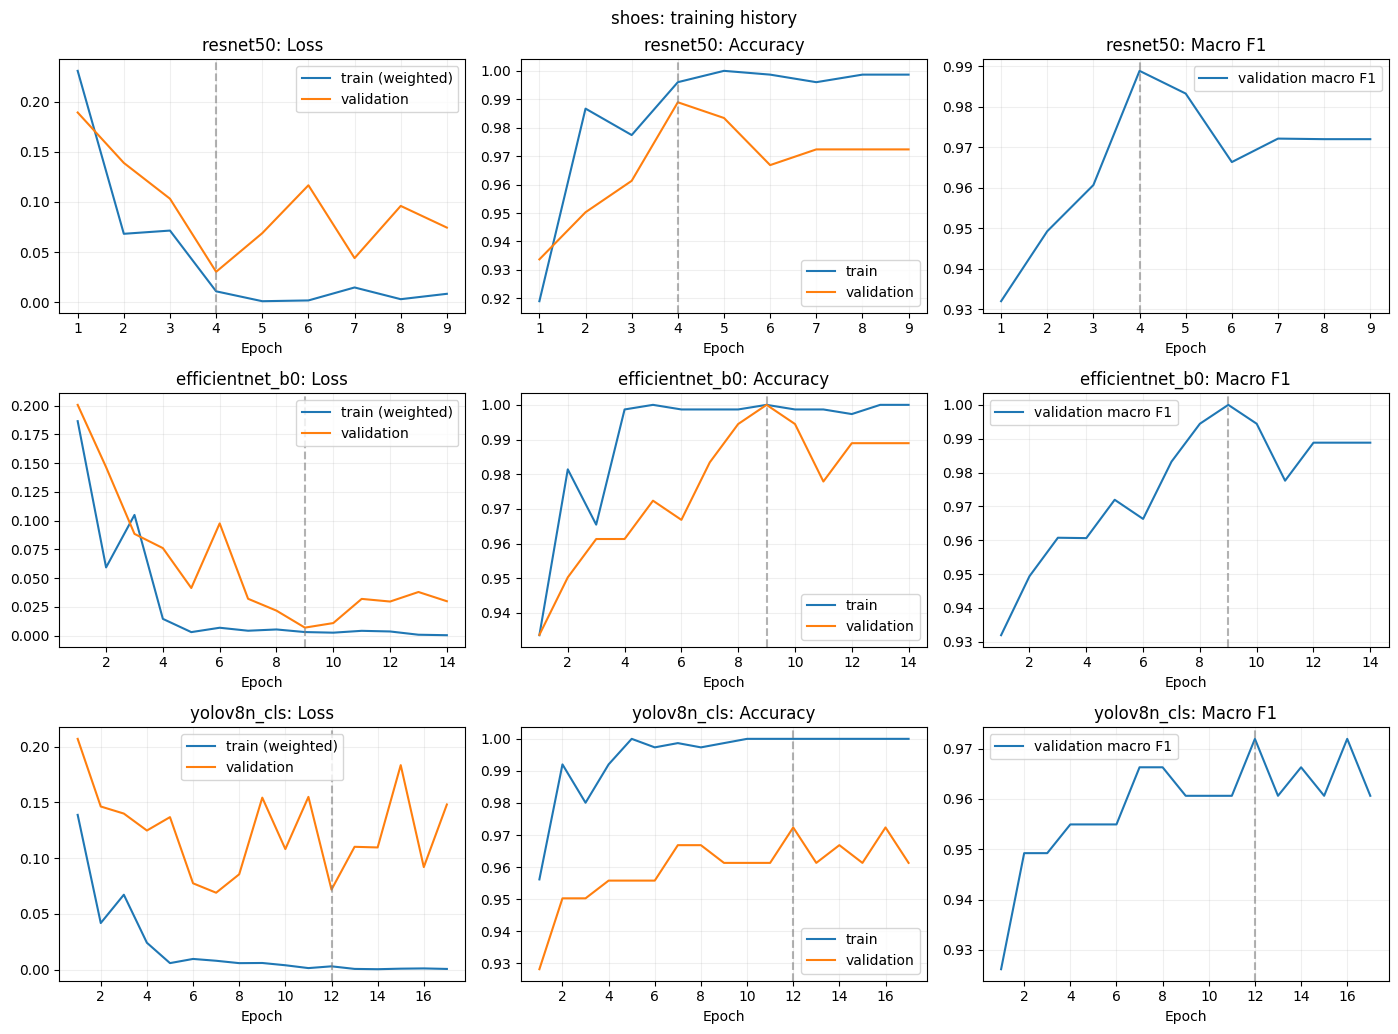

In [ ]:
for task in TASK_CLASSES:
    fig,axes = plt.subplots(len(MODEL_NAMES),3,figsize=(14,3.5*len(MODEL_NAMES)),squeeze=False)
    for row,name in enumerate(MODEL_NAMES):
        history = pd.read_csv(RUN_DIR/task/name/'history.csv')
        best_epoch = int(history.loc[history.val_macro_f1.idxmax(),'epoch'])
        axes[row,0].plot(history.epoch,history.train_loss,label='train (weighted)')
        axes[row,0].plot(history.epoch,history.val_loss,label='validation')
        axes[row,1].plot(history.epoch,history.train_accuracy,label='train')
        axes[row,1].plot(history.epoch,history.val_accuracy,label='validation')
        axes[row,2].plot(history.epoch,history.val_macro_f1,label='validation macro F1')
        for ax,title in zip(axes[row],['Loss','Accuracy','Macro F1']):
            ax.axvline(best_epoch,color='gray',linestyle='--',alpha=.6)
            ax.set_title(f'{name}: {title}'); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2)
    plt.suptitle(f'{task}: training history'); plt.tight_layout()
    plt.savefig(RUN_DIR/f'{task}_learning_curves.png',dpi=150); plt.show()


## Held-out evaluation

Class 1 is `no_mask` or `no_shoes`. Prediction uses argmax, equivalent to a fixed 0.5 missing-class threshold for two classes. No test-set threshold search.

Export per-class precision, recall, F1, support, confusion matrices, ROC AUC, average precision, and raw predictions. Macro F1 weights the two classes equally; balanced accuracy averages class recall.

The missing-recall Wilson interval is descriptive at crop level. Correlated frames violate its independence assumption, so it is not a session-level confidence interval.


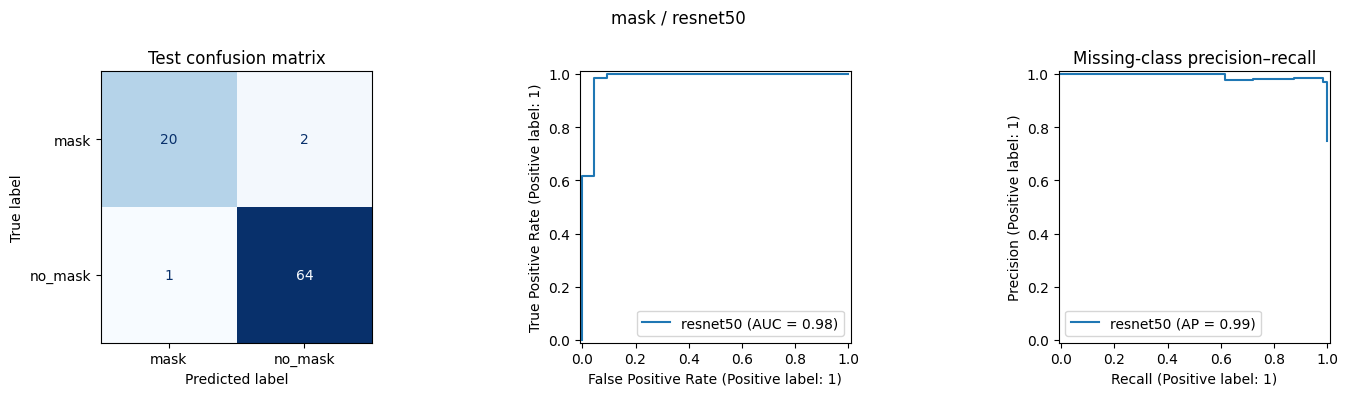

,precision,recall,f1-score,support
mask,0.952381,0.909091,0.930233,22.000000
no_mask,0.969697,0.984615,0.977099,65.000000
accuracy,0.965517,0.965517,0.965517,0.965517
macro avg,0.961039,0.946853,0.953666,87.000000
weighted avg,0.965318,0.965517,0.965248,87.000000


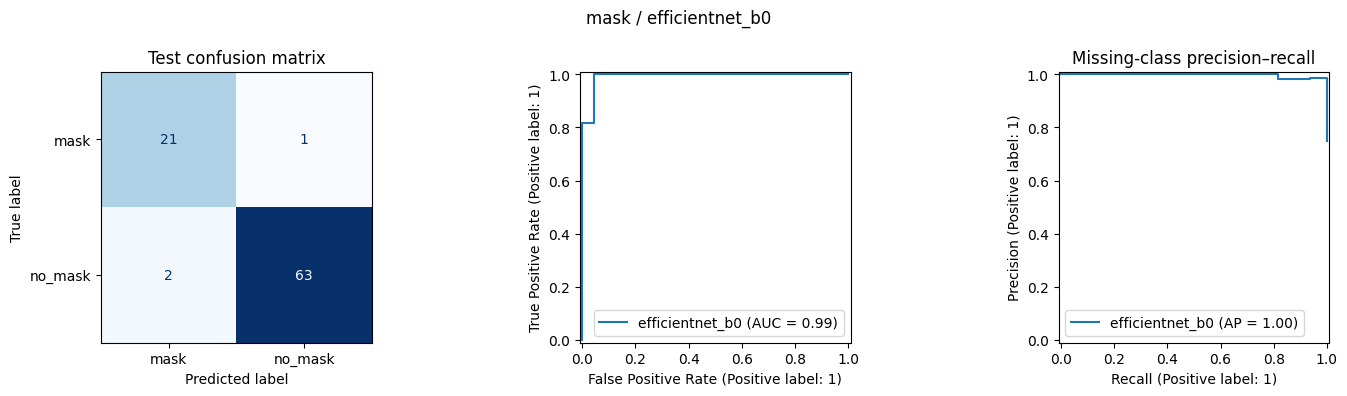

,precision,recall,f1-score,support
mask,0.913043,0.954545,0.933333,22.000000
no_mask,0.984375,0.969231,0.976744,65.000000
accuracy,0.965517,0.965517,0.965517,0.965517
macro avg,0.948709,0.961888,0.955039,87.000000
weighted avg,0.966337,0.965517,0.965767,87.000000


YOLOv8n-cls summary: 56 layers, 2,719,288 parameters, 2,719,288 gradients, 3.4 GFLOPs


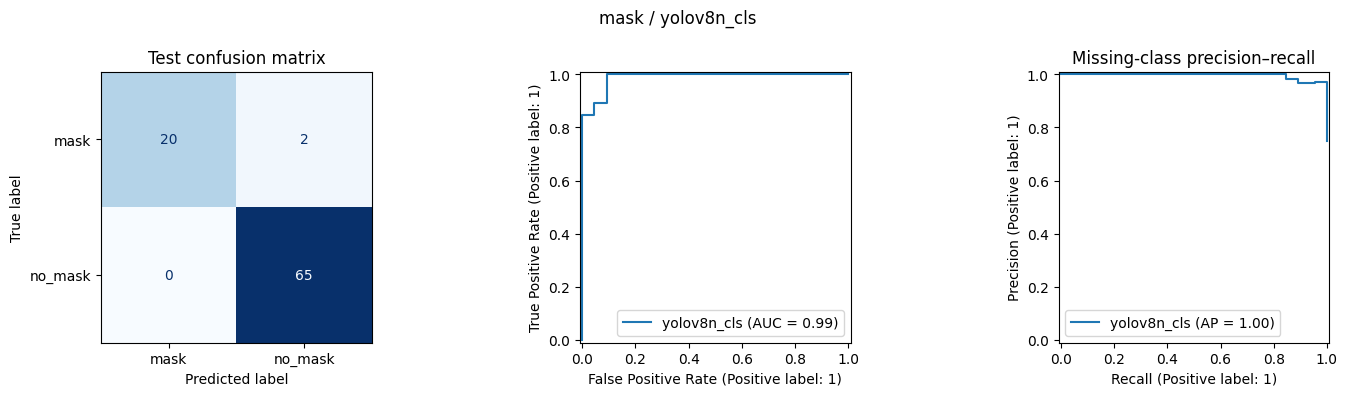

,precision,recall,f1-score,support
mask,1.000000,0.909091,0.952381,22.000000
no_mask,0.970149,1.000000,0.984848,65.000000
accuracy,0.977011,0.977011,0.977011,0.977011
macro avg,0.985075,0.954545,0.968615,87.000000
weighted avg,0.977698,0.977011,0.976638,87.000000


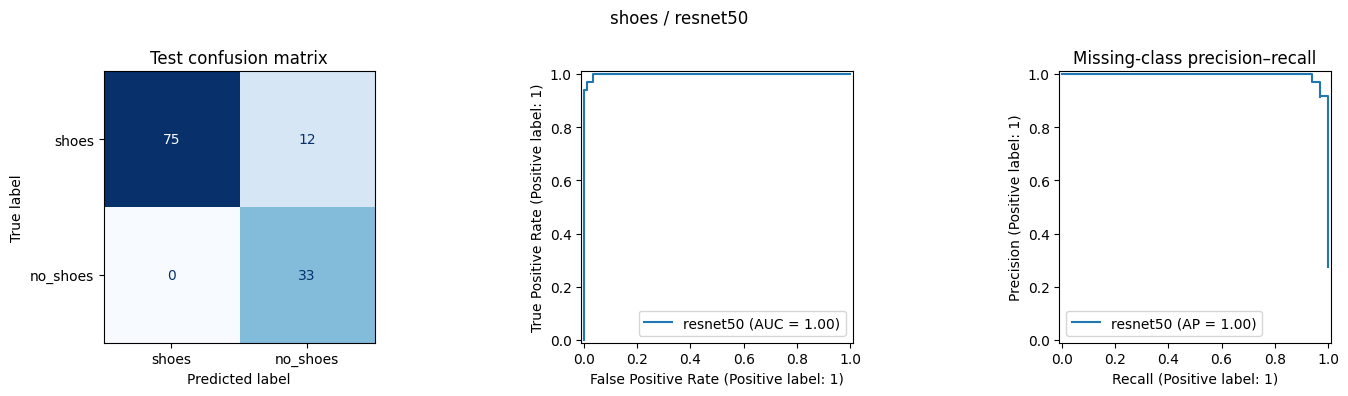

,precision,recall,f1-score,support
shoes,1.000000,0.862069,0.925926,87.0
no_shoes,0.733333,1.000000,0.846154,33.0
accuracy,0.900000,0.900000,0.900000,0.9
macro avg,0.866667,0.931034,0.886040,120.0
weighted avg,0.926667,0.900000,0.903989,120.0


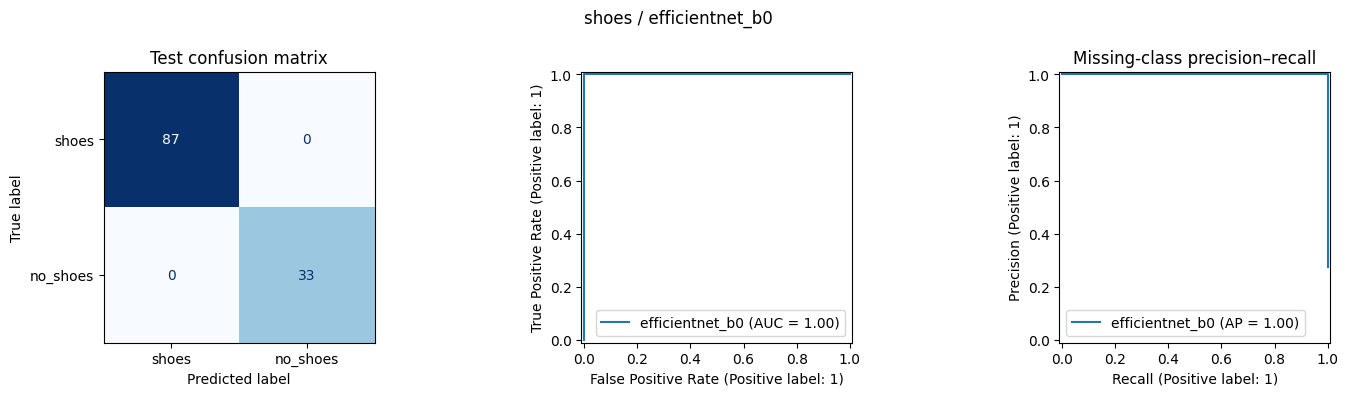

,precision,recall,f1-score,support
shoes,1.0,1.0,1.0,87.0
no_shoes,1.0,1.0,1.0,33.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,120.0
weighted avg,1.0,1.0,1.0,120.0


YOLOv8n-cls summary: 56 layers, 2,719,288 parameters, 2,719,288 gradients, 3.4 GFLOPs


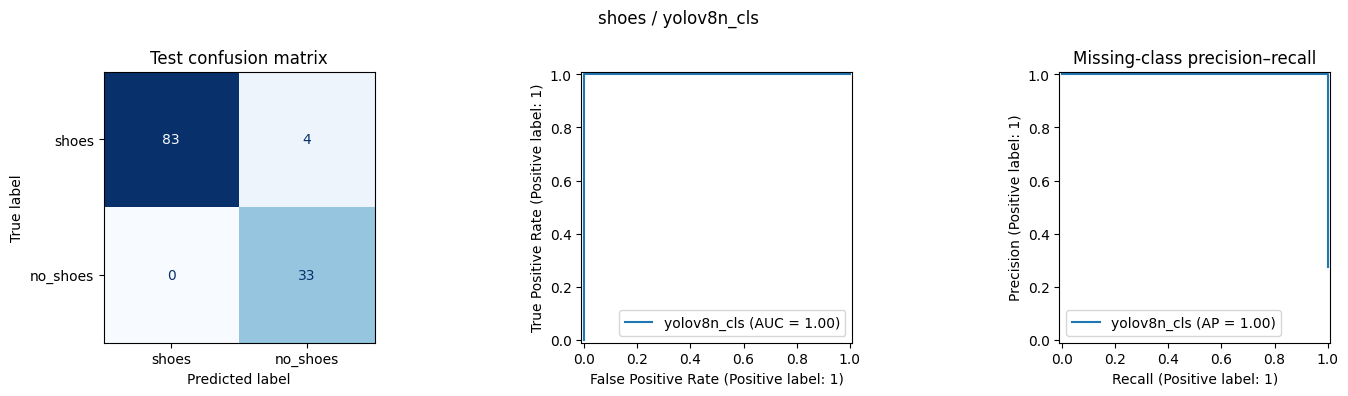

,precision,recall,f1-score,support
shoes,1.000000,0.954023,0.976471,87.000000
no_shoes,0.891892,1.000000,0.942857,33.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.945946,0.977011,0.959664,120.000000
weighted avg,0.970270,0.966667,0.967227,120.000000


In [ ]:
def restore_model(path):
    checkpoint = load_checkpoint(path)
    model = build_model(checkpoint['architecture'],pretrained=False)
    model.load_state_dict(checkpoint['model_state']); model.eval()
    return model,checkpoint

def wilson_interval(successes,total,z=1.96):
    if total == 0: return [None,None]
    p = successes/total; denom = 1+z*z/total
    center = (p+z*z/(2*total))/denom
    radius = z*math.sqrt(p*(1-p)/total+z*z/(4*total*total))/denom
    return [center-radius,center+radius]

def benchmark_forward(model,image_tensor,repeats=30):
    image_tensor = image_tensor.unsqueeze(0).to(DEVICE)
    def sync():
        if DEVICE.type=='cuda': torch.cuda.synchronize()
    durations = []
    with torch.inference_mode():
        for _ in range(5): get_logits(model,image_tensor)
        sync()
        for _ in range(repeats):
            sync(); begin = time.perf_counter(); get_logits(model,image_tensor); sync()
            durations.append(1000*(time.perf_counter()-begin))
    return {'forward_median_ms':float(np.median(durations)),
            'forward_p90_ms':float(np.percentile(durations,90)), 'benchmark_device':str(DEVICE)}

def test_one(task,name):
    folder = RUN_DIR/task/name
    best_path = folder/'best.pt'
    signature = {'checkpoint_sha256':sha256_file(best_path),'data_fingerprint':DATA_FINGERPRINT}
    cached_path = folder/'test_metrics.json'
    if cached_path.exists():
        cached = json.loads(cached_path.read_text())
        if cached.get('signature') == signature:
            print('Using cached test evaluation:',task,name)
            if (folder/'test_evaluation.png').exists():
                display(Image.open(folder/'test_evaluation.png').copy())
            if (folder/'classification_report.json').exists():
                display(pd.DataFrame(json.loads((folder/'classification_report.json').read_text())).T)
            return cached
        raise ValueError('Test was already evaluated with another checkpoint/data. Use a new experiment and report any repeated test use.')
    model,checkpoint = restore_model(best_path)
    rows = manifest[(manifest.label.isin(TASK_CLASSES[task])) & (manifest.split=='test')].reset_index(drop=True)
    loader = make_loader(rows,task,name)
    output = evaluate_loader(model,loader,nn.CrossEntropyLoss())
    y,pred,prob = output['y'],output['pred'],output['probabilities'][:,1]
    precision,recall,f1,support = precision_recall_fscore_support(y,pred,labels=[0,1],zero_division=0)
    cm = confusion_matrix(y,pred,labels=[0,1])
    report = classification_report(y,pred,labels=[0,1],target_names=TASK_CLASSES[task],output_dict=True,zero_division=0)
    (folder/'classification_report.json').write_text(json.dumps(report,indent=2))
    predictions = rows[['source_id','group','crop_path','label']].copy()
    predictions['true_id'] = y; predictions['predicted_id'] = pred
    predictions['probability_missing'] = prob
    predictions['predicted_label'] = [TASK_CLASSES[task][i] for i in pred]
    predictions.to_csv(folder/'test_predictions.csv',index=False)
    metrics = {'task':task,'model':name,'test_accuracy':float(output['accuracy']),
        'test_macro_f1':float(output['macro_f1']),
        'test_balanced_accuracy':float(balanced_accuracy_score(y,pred)),
        'missing_precision':float(precision[1]),'missing_recall':float(recall[1]),
        'missing_f1':float(f1[1]),'roc_auc':float(roc_auc_score(y,prob)),
        'average_precision_missing':float(average_precision_score(y,prob)),
        'test_crops':len(y),'test_groups':rows.group.nunique(),
        'missing_support':int(support[1]),'present_support':int(support[0]),
        'false_missing':int(cm[0,1]),'missed_missing':int(cm[1,0]),
        'missing_recall_wilson95_crop_level':wilson_interval(int(cm[1,1]),int(support[1])),
        'best_epoch':checkpoint['epoch']+1,'best_val_macro_f1':checkpoint['best_score'],
        'parameters':sum(p.numel() for p in model.parameters()),'signature':signature,
        'checkpoint_mb':best_path.stat().st_size/(1024**2)}
    metrics.update(benchmark_forward(model,loader.dataset[0][0]))
    fig,axes = plt.subplots(1,3,figsize=(15,4))
    ConfusionMatrixDisplay(cm,display_labels=TASK_CLASSES[task]).plot(ax=axes[0],colorbar=False,cmap='Blues')
    RocCurveDisplay.from_predictions(y,prob,ax=axes[1],name=name)
    PrecisionRecallDisplay.from_predictions(y,prob,ax=axes[2],name=name)
    axes[0].set_title('Test confusion matrix'); axes[2].set_title('Missing-class precision–recall')
    plt.suptitle(f'{task} / {name}'); plt.tight_layout()
    plt.savefig(folder/'test_evaluation.png',dpi=150); plt.show()
    display(pd.DataFrame(report).T)
    cached_path.write_text(json.dumps(metrics,indent=2))
    del model
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
    return metrics

test_results = [test_one(task,name) for task in TASK_CLASSES for name in MODEL_NAMES]


## Model comparison

Sort by validation macro F1 within each task. Report held-out scores for the fixed checkpoints. This is one seed with inferred source groups; repeat across seeds and independent sessions before drawing architecture-level conclusions.

Latency is a warmed-up, batch-one network forward pass on the recorded device. It excludes capture, detection, cropping, preprocessing, and task rules. It is not an end-to-end or Raspberry Pi benchmark.


,task,model,best_epoch,best_val_macro_f1,test_accuracy,test_macro_f1,missing_precision,missing_recall,missing_f1,test_crops,test_groups,parameters,checkpoint_mb,forward_median_ms,forward_p90_ms,benchmark_device
0,mask,resnet50,4,1.0000,0.9655,0.9537,0.9697,0.9846,0.9771,87,3,23512130,89.9794,10.2880,12.7651,cuda
1,mask,efficientnet_b0,1,1.0000,0.9655,0.9550,0.9844,0.9692,0.9767,87,3,4010110,15.5651,10.9273,15.7647,cuda
2,mask,yolov8n_cls,2,1.0000,0.9770,0.9686,0.9701,1.0000,0.9848,87,3,1440850,5.5675,3.4685,3.7091,cuda
4,shoes,efficientnet_b0,9,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,120,4,4010110,15.5658,9.0907,10.4232,cuda
3,shoes,resnet50,4,0.9888,0.9000,0.8860,0.7333,1.0000,0.8462,120,4,23512130,89.9794,6.7397,7.0729,cuda
5,shoes,yolov8n_cls,12,0.9720,0.9667,0.9597,0.8919,1.0000,0.9429,120,4,1440850,5.5684,3.6611,3.9587,cuda


Validation-selected models: {'mask': 'resnet50', 'shoes': 'efficientnet_b0'}


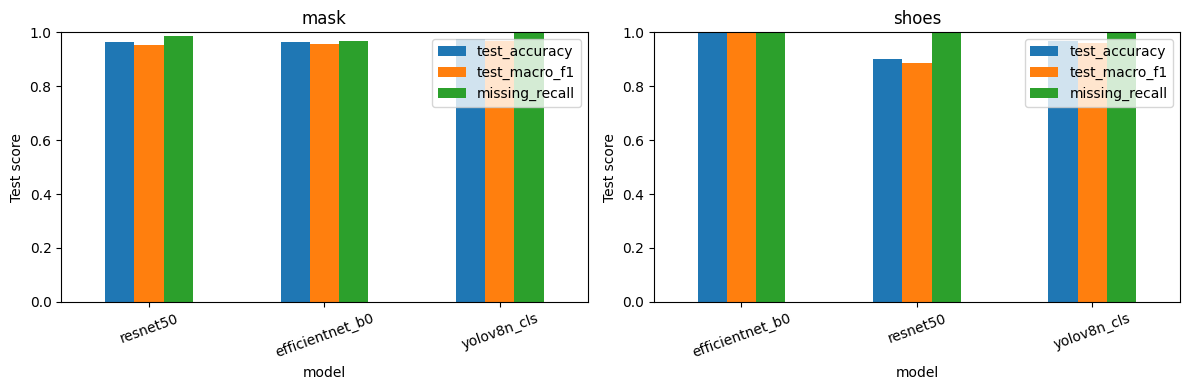

In [ ]:
comparison = pd.DataFrame(test_results).sort_values(['task','best_val_macro_f1'],ascending=[True,False])
comparison.to_csv(RUN_DIR/'model_comparison.csv',index=False)
columns = ['task','model','best_epoch','best_val_macro_f1','test_accuracy','test_macro_f1',
    'missing_precision','missing_recall','missing_f1','test_crops','test_groups',
    'parameters','checkpoint_mb','forward_median_ms','forward_p90_ms','benchmark_device']
display(comparison[columns].round(4))
selected = comparison.groupby('task',sort=False).head(1)
print('Validation-selected models:',dict(zip(selected.task,selected.model)))

fig,axes = plt.subplots(1,2,figsize=(12,4))
for ax,task in zip(axes,TASK_CLASSES):
    part = comparison[comparison.task==task].set_index('model')
    part[['test_accuracy','test_macro_f1','missing_recall']].plot.bar(ax=ax,ylim=(0,1))
    ax.set_title(task); ax.set_ylabel('Test score'); ax.tick_params(axis='x',rotation=20)
plt.tight_layout(); plt.savefig(RUN_DIR/'test_comparison.png',dpi=150); plt.show()


## Error inspection

Document test failures after the final evaluation. Subsequent model changes require a fresh final test set. Review small or blurred regions, detached items, annotation errors, context bias, and source-group differences. Confidence scores are uncalibrated.


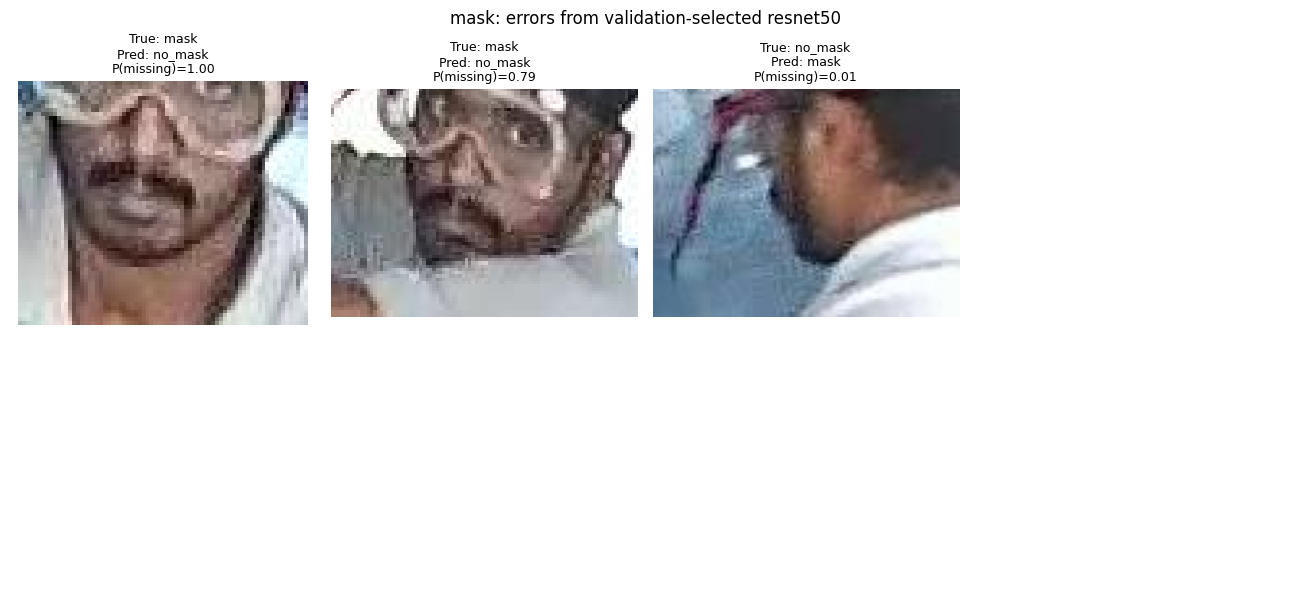

shoes : no errors in this test sample; this does not prove perfect real-world performance.


In [ ]:
for selected_row in selected.itertuples():
    folder = RUN_DIR/selected_row.task/selected_row.model
    predictions = pd.read_csv(folder/'test_predictions.csv')
    mistakes = predictions[predictions.true_id != predictions.predicted_id].head(8)
    if mistakes.empty:
        print(selected_row.task,': no errors in this test sample; this does not prove perfect real-world performance.')
        continue
    fig,axes = plt.subplots(2,4,figsize=(13,6))
    for ax in axes.flat: ax.axis('off')
    for ax,row in zip(axes.flat,mistakes.itertuples()):
        ax.imshow(Image.open(row.crop_path))
        ax.set_title(f'True: {row.label}\nPred: {row.predicted_label}\nP(missing)={row.probability_missing:.2f}',fontsize=9)
    plt.suptitle(f'{selected_row.task}: errors from validation-selected {selected_row.model}')
    plt.tight_layout(); plt.savefig(folder/'test_error_examples.png',dpi=150); plt.show()


## Checkpoint inference

`predict_crop()` reloads architecture, class order, image size, and weights. Input must be a face region for mask classification or a foot/shoe region for footwear classification. Full-scene inference requires a separate detection/crop stage. Returned probabilities are uncalibrated scores.


In [ ]:
def predict_crop(checkpoint_path,image_path):
    model,checkpoint = restore_model(Path(checkpoint_path))
    name = checkpoint['architecture']
    size = checkpoint['image_size']
    steps = [SquarePadResize(size),transforms.ToTensor()]
    if name != 'yolov8n_cls':
        steps += [transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]
    with Image.open(image_path) as image:
        tensor = transforms.Compose(steps)(image.convert('RGB')).unsqueeze(0).to(DEVICE)
    with torch.inference_mode(): probabilities = get_logits(model,tensor).softmax(1)[0].cpu().tolist()
    result = dict(zip(checkpoint['classes'],probabilities))
    del model
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
    return result

CUSTOM_IMAGE_PATH = ''  # Face crop for mask; foot region for shoes.
CUSTOM_TASK = 'mask'   # Select the matching checkpoint task.
if CUSTOM_IMAGE_PATH:
    chosen = selected[selected.task==CUSTOM_TASK].iloc[0]
    checkpoint_path = RUN_DIR/CUSTOM_TASK/chosen.model/'best.pt'
    display(predict_crop(checkpoint_path,CUSTOM_IMAGE_PATH))
else:
    print('Optional: set CUSTOM_IMAGE_PATH to a region image, then rerun this cell.')


Optional: set CUSTOM_IMAGE_PATH to a region image, then rerun this cell.


## Export

Write metrics, dataset revision, split fingerprint, and experiment limitations to `results_report.md`.

The ZIP contains six best checkpoints, histories, reports, predictions, manifests, and plots. Source archives, crop images, temporary files, and `last.pt` resume checkpoints are excluded. Resume files remain in `RUN_DIR`.


In [ ]:
report_lines = [
    '# PPE classification baseline results', '',
    f'Run: {EXPERIMENT_NAME}_{RUN_MODE}',
    f'Dataset: {DATASET_REPO}, revision {DATASET_REVISION}',
    'Source: Personal Protective Equipment, PPEs dataset version 7, CC BY 4.0.',
    'Protocol: pooled source archives; rebuilt shared source-group splits; ImageNet fine-tuning.',
    f'Split fingerprint: {DATA_FINGERPRINT}', '',
    '## Validation-selected models', '',
]
for row in selected.itertuples():
    report_lines += [
        f'- {row.task}: {row.model}; best epoch {row.best_epoch}; validation macro F1 {row.best_val_macro_f1:.4f}; '
        f'test accuracy {row.test_accuracy:.4f}; test macro F1 {row.test_macro_f1:.4f}; '
        f'missing precision {row.missing_precision:.4f}; missing recall {row.missing_recall:.4f}; '
        f'{row.test_crops} test crops from {row.test_groups} inferred source groups.'
    ]
report_lines += ['', '## Interpretation and limits', '',
    'The labels describe mask/no-mask and shoes/no-shoes region appearance, not task-specific compliance.',
    'Some shoe annotations show detached shoes; protective certification and correct wearing are not established.',
    'Automatic source grouping cannot prove worker/session independence without original recording metadata.',
    'One training seed and this public dataset do not establish robustness in AW Rostamani repair bays.',
    'Latency measures batch-one network forward passes only, excluding the camera and preprocessing.',
    'The test set was not used for checkpoint selection. Models were selected by validation macro F1.',
    'Next: obtain site-approved task rules and independent workshop/session data, verify labels, then test the full pipeline.', '',
    '## Student discussion prompts', '',
    '- Which model would you choose from validation performance, model size, and measured device latency, and why?',
    '- Which class/source group is hardest? What error examples support your explanation?',
    '- How do train/validation curves suggest overfitting or limited learning?',
    '- What does this dataset allow you to claim, and what requires new workshop evidence?', '',
    '## Sources', '',
    'https://universe.roboflow.com/personal-protective-equipment/ppes-kaxsi/dataset/7',
    'https://huggingface.co/datasets/keremberke/protective-equipment-detection',
    'https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html',
    'https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b0.html',
    'https://docs.ultralytics.com/models/yolov8/',
    'https://docs.ultralytics.com/tasks/classify/',
]
(RUN_DIR/'results_report.md').write_text('\n'.join(report_lines),encoding='utf-8')
export_path = BASE_DIR/f'{EXPERIMENT_NAME}_{RUN_MODE}_results.zip'
with zipfile.ZipFile(export_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in RUN_DIR.rglob('*'):
        if path.is_file() and path.name != 'last.pt' and path.suffix != '.tmp':
            z.write(path,path.relative_to(RUN_DIR))
print('Saved report:',RUN_DIR/'results_report.md')
print('Export ZIP:',export_path, f'({export_path.stat().st_size/1024**2:.1f} MB)')
display(Markdown((RUN_DIR/'results_report.md').read_text(encoding='utf-8')))

# Optional download from Colab.
# from google.colab import files
# files.download(str(export_path))


Saved report: /content/drive/MyDrive/PPE_Classification/runs/baseline_v1_full/results_report.md
Export ZIP: /content/drive/MyDrive/PPE_Classification/baseline_v1_full_results.zip (206.9 MB)


# PPE classification baseline results

Run: baseline_v1_full
Dataset: keremberke/protective-equipment-detection, revision 90d2c6da950a6168fcee20ec69e194a034f44eef
Source: Personal Protective Equipment, PPEs dataset version 7, CC BY 4.0.
Protocol: pooled source archives; rebuilt shared source-group splits; ImageNet fine-tuning.
Split fingerprint: d34082cdfc862dd8c059a0f79382e6f85985bc6828f98122bb1e29c1a5834c19

## Validation-selected models

- mask: resnet50; best epoch 4; validation macro F1 1.0000; test accuracy 0.9655; test macro F1 0.9537; missing precision 0.9697; missing recall 0.9846; 87 test crops from 3 inferred source groups.
- shoes: efficientnet_b0; best epoch 9; validation macro F1 1.0000; test accuracy 1.0000; test macro F1 1.0000; missing precision 1.0000; missing recall 1.0000; 120 test crops from 4 inferred source groups.

## Interpretation and limits

The labels describe mask/no-mask and shoes/no-shoes region appearance, not task-specific compliance.
Some shoe annotations show detached shoes; protective certification and correct wearing are not established.
Automatic source grouping cannot prove worker/session independence without original recording metadata.
One training seed and this public dataset do not establish robustness in AW Rostamani repair bays.
Latency measures batch-one network forward passes only, excluding the camera and preprocessing.
The test set was not used for checkpoint selection. Models were selected by validation macro F1.
Next: obtain site-approved task rules and independent workshop/session data, verify labels, then test the full pipeline.

## Student discussion prompts

- Which model would you choose from validation performance, model size, and measured device latency, and why?
- Which class/source group is hardest? What error examples support your explanation?
- How do train/validation curves suggest overfitting or limited learning?
- What does this dataset allow you to claim, and what requires new workshop evidence?

## Sources

https://universe.roboflow.com/personal-protective-equipment/ppes-kaxsi/dataset/7
https://huggingface.co/datasets/keremberke/protective-equipment-detection
https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html
https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b0.html
https://docs.ultralytics.com/models/yolov8/
https://docs.ultralytics.com/tasks/classify/

## Run notes

| Issue | Action |
|---|---|
| CPU runtime | Use quick mode for a smoke run; full comparison used a Colab GPU. |
| Failed download | Rerun; completed archives are checksum-verified and reused. |
| Import failure after install | Restart the kernel and rerun from imports. |
| Insufficient source groups | Inspect group coverage and collect additional sessions. |
| Saved configuration mismatch | Use a new `EXPERIMENT_NAME`. |
| GPU memory exhausted | Restart, reduce batch size, and use a new experiment name. |
| Colab disconnect | Remount Drive and rerun in order; training resumes after completed epochs. |

Retain `model_comparison.csv`, `results_report.md`, plots, and each `best.pt` together with `run_config.json`, `environment.json`, and `split_manifest.csv`. Checkpoints and the full results ZIP are separate artifacts; embedded notebook outputs do not contain them.
